# 03 · CH₂OO: first steps with a fragment-channel frame

The simplest Criegee intermediate, H₂C=O⁺–O⁻ ↔ ·H₂C–O–O·, is the case the whole approach is aimed at. Its ground
state mixes **zwitterionic** and **biradical** character; its O–O bond breaks to CH₂O + O(¹D) on singlet surfaces,
with the biradical channel CH₂O(T₁) + O(³P) and the ion pair CH₂O⁺ + O⁻ above.

**Reference data**: SA4-CASSCF(8,6)/6-31G\*, the four lowest singlet A′ states on a planar grid of r(O–O) and ∠COO, with
the CH₂O fragment held rigid (`diabml.refs.ch2oo`, ~20 min). Each state also carries two diagnostics: the
Mulliken charge on the terminal O (zwitterion character) and the effective number of unpaired electrons
(biradical character).

**The frame** (`diabml.frames.ChannelFrame`): five structures labelled by the fragment states they dissociate to.

| Structure | Asymptote from | Long-range form |
|---|---|---|
| CH₂O(S₀) + O(¹D), three A′ components | the three lowest states at 8 Å | constant |
| CH₂O(T₁) + O(³P), singlet-coupled (biradical) | the fourth state at 8 Å | constant |
| CH₂O⁺ + O⁻ (zwitterion) | **the ladder**: IE(CH₂O) − EA(O) − ΔE(¹D−³P) | −14.40 / r Coulomb |

Every learned part is multiplied by an O–O overlap envelope that decays as the O leaves, and the network sees
overlap features that saturate at long range, so the asymptotes and the Coulomb tail are exact by construction and
the network cannot extrapolate wildly beyond its data (the descriptor lesson of the first exploratory notebook). This is a *minimal* frame: correct structures, limits and long-range physics, with all
short-range shape learned.

In [1]:
# ---------------- controls ----------------
N_STATES  = 4            # adiabatic states fitted (lowest N of the 5-structure matrix)
EPOCHS    = 6000
RESTARTS  = 2
LADDER    = 'experiment' # 'experiment' (IE 10.88, EA 1.461, 1D-3P 1.967 eV) or 'compute' (delta-CCSD(T)/aug-cc-pVTZ, minutes)
R_TRAIN_MAX = 2.3        # extrapolation test: train only on r(O-O) <= this (Angstrom)

In [2]:
import sys, time, numpy as np, torch, matplotlib.pyplot as plt
sys.path.insert(0, '..')                      # the diabml package lives one level up
from diabml import RefSet
from diabml.units import EV_KCAL
from diabml import plotting as P, metrics as M
from diabml.models import CDNN, IndependentNN, FramedModel, KRR, train
P.style()
torch.set_num_threads(2)
DATA = '../data/'
from diabml.frames import ChannelFrame, Diabat
ref = RefSet.load(DATA + 'ch2oo_casscf.npz')
print(ref); print(ref.meta['method'])
print('all converged:', bool(ref.extra['converged'].all()), '| active space consistent:', bool(ref.extra['active_space_consistent'].all()))
r, a = ref.coords[:, 0], ref.coords[:, 1]

RefSet('CH2OO SA4-CASSCF(8,6)/6-31G*', 120 geometries, 4 states, coords=['r_OO', 'a_COO'], extras=['active_space_consistent', 'converged', 'n_unpaired', 'q_O_terminal'])
SA4-CASSCF(8,6)/6-31G*, singlet A' (Cs), planar, CH2O fragment rigid
all converged: True | active space consistent: True


## What the states are

Along the O–O stretch at the equilibrium angle: energies, charge separation and open-shell character of each state.

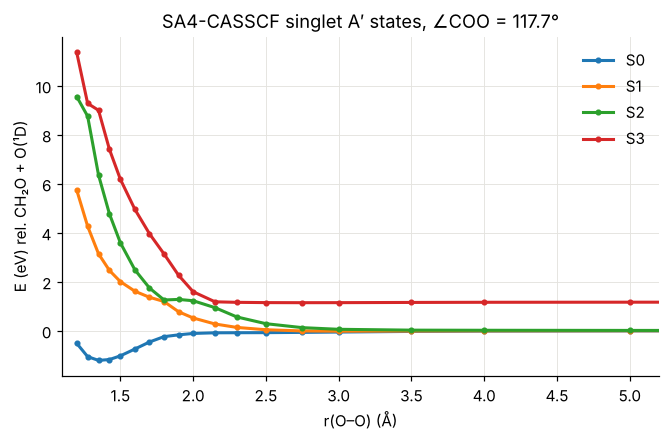

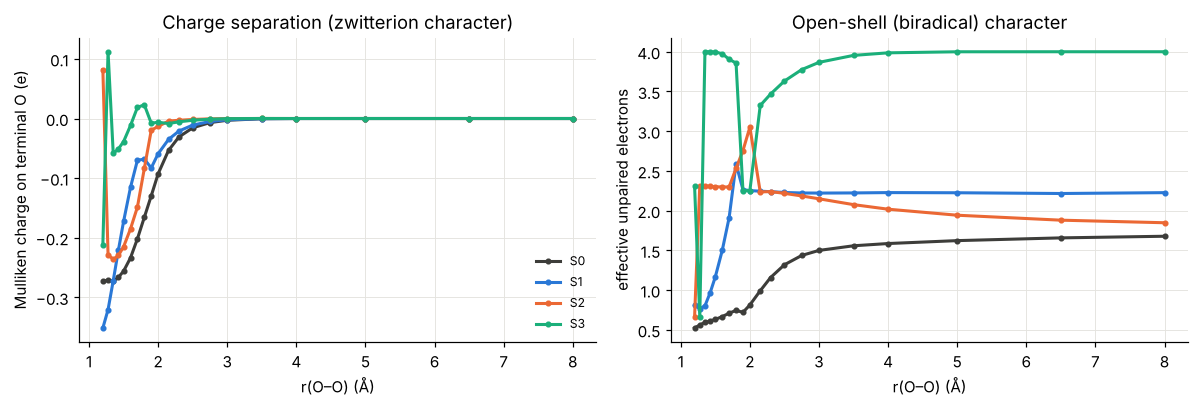

In [3]:
eq = np.where(np.isclose(a, 117.7))[0]; eq = eq[np.argsort(r[eq])]
fig, ax = plt.subplots(figsize=(7, 4))
for s in range(ref.n_states):
    ax.plot(r[eq], ref.energies[eq, s], marker='o', ms=3, label=f'S{s}')
ax.set(xlabel='r(O–O) (Å)', ylabel='E (eV) rel. CH₂O + O(¹D)', title='SA4-CASSCF singlet A′ states, ∠COO = 117.7°', xlim=(1.1, 5.2))
ax.legend(); plt.show()
P.character_plot(r[eq], ref.extra['q_O_terminal'][eq], ref.extra['n_unpaired'][eq]); plt.show()

## The ladder: anchoring the ionic structure

The zwitterion H₂C=O⁺–O⁻ dissociates diabatically to CH₂O⁺ + O⁻. Its asymptote, relative to CH₂O + O(¹D), needs
exactly the charge- and spin-state data the electron ladder is about: the ionisation energy of the fragment, the
electron affinity of O, and the O(¹D)–O(³P) splitting. Where it crosses the covalent structures is then fixed by
Coulomb's law, r* ≈ 14.40 eV·Å / ΔE.

In [4]:
if LADDER == 'compute':
    from diabml.refs.ladder import compute
    lad = compute(); dE_ion = lad['dE_ion']; print(lad)
else:
    from diabml.refs.ladder import EXPERIMENT as X
    dE_ion = X['IE_CH2O_adiabatic'] - X['EA_O'] - X['O_1D_3P']
far = np.where(r == r.max())[0]
asym = ref.energies[far].mean(0)
print(f'asymptotes at 8 Å (eV): {np.round(asym, 3)}  |  ion pair: {dE_ion:.2f} eV  ->  Coulomb crossing near {14.40 / dE_ion:.2f} Å')
diabats = [Diabat('CH₂O + O(¹D) a', asym[0]), Diabat('CH₂O + O(¹D) b', asym[1]), Diabat('CH₂O + O(¹D) c', asym[2]),
           Diabat('CH₂O(T₁) + O(³P)', asym[3], kind='biradical'),
           Diabat('CH₂O⁺ + O⁻', asym[:3].mean() + dE_ion, charge_product=-1.0, kind='ionic')]
def new_frame():
    return ChannelFrame(diabats, n_coords=2, r_index=0)

asymptotes at 8 Å (eV): [1.000e-03 5.000e-03 1.200e-02 1.171e+00]  |  ion pair: 7.45 eV  ->  Coulomb crossing near 1.93 Å


## Test 1 · Interpolation (random split)

In [5]:
tr, va, te = ref.split(70, 15, seed=0)
t0 = time.time()
fr = new_frame()
framed = train(FramedModel(fr, N_STATES, hidden=(128, 64)), ref.coords[tr], ref.energies[tr], ref.coords[va], ref.energies[va],
               epochs=EPOCHS, lr=2e-3, restarts=RESTARTS)
cdnn = train(CDNN(2, N_STATES, n_matrix=5, hidden=(128, 64)), ref.coords[tr], ref.energies[tr], ref.coords[va], ref.energies[va],
             epochs=EPOCHS, lr=1e-3, restarts=RESTARTS)
print(f'trained in {time.time() - t0:.0f} s')
for k, m in [('framed CDNN', framed), ('CDNN', cdnn)]:
    print(f'{k:12s} test RMSE per state (kcal/mol):', np.round(M.rmse_kcal(m.predict(ref.coords[te]), ref.energies[te]), 2))

trained in 57 s
framed CDNN  test RMSE per state (kcal/mol): [2.69 3.55 6.81 7.06]
CDNN         test RMSE per state (kcal/mol): [1.17 1.65 5.37 6.13]


## Test 2 · Extrapolation to dissociation

Train only on r(O–O) ≤ `R_TRAIN_MAX`, then predict the whole stretch. This is the situation of a data set built from
trajectories that rarely reach full dissociation. The frame knows the asymptotes; plain CDNN has to guess.

framed CDNN  RMSE beyond 2.3 Å (kcal/mol): [3.1 2.8 2.6 7.1]
CDNN         RMSE beyond 2.3 Å (kcal/mol): [109.4  59.7 112.3 221.1]


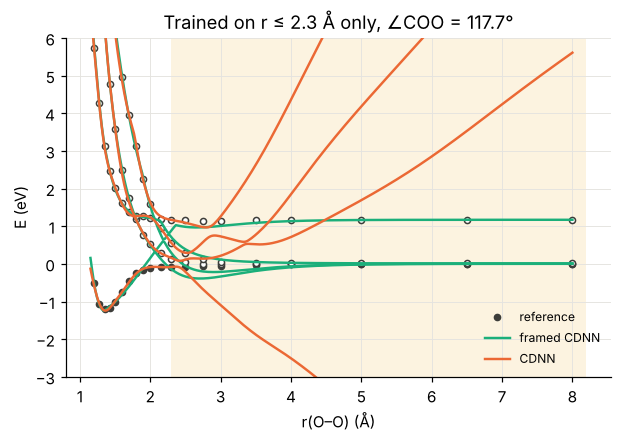

In [6]:
inner = np.where(r <= R_TRAIN_MAX)[0]; outer = np.where(r > R_TRAIN_MAX)[0]
p = np.random.default_rng(1).permutation(inner); tr2, va2 = p[:int(0.8 * len(p))], p[int(0.8 * len(p)):]
fr2 = new_frame()
framed2 = train(FramedModel(fr2, N_STATES, hidden=(128, 64)), ref.coords[tr2], ref.energies[tr2], ref.coords[va2], ref.energies[va2],
                epochs=EPOCHS, lr=2e-3, restarts=RESTARTS)
cdnn2 = train(CDNN(2, N_STATES, n_matrix=5, hidden=(128, 64)), ref.coords[tr2], ref.energies[tr2], ref.coords[va2], ref.energies[va2],
              epochs=EPOCHS, lr=1e-3, restarts=RESTARTS)
for k, m in [('framed CDNN', framed2), ('CDNN', cdnn2)]:
    print(f'{k:12s} RMSE beyond {R_TRAIN_MAX} Å (kcal/mol):', np.round(M.rmse_kcal(m.predict(ref.coords[outer]), ref.energies[outer]), 1))
x = np.linspace(1.15, 8.0, 300); C = np.c_[x, np.full_like(x, 117.7)]
ax = P.cut_plot(x, ref.energies[eq], {'framed CDNN': framed2.predict(C), 'CDNN': cdnn2.predict(C)}, 'r(O–O) (Å)', 'E (eV)',
                title=f'Trained on r ≤ {R_TRAIN_MAX} Å only, ∠COO = 117.7°', ref_x=r[eq]).axes[0]
ax.axvspan(R_TRAIN_MAX, 8.2, color='#eda100', alpha=0.12, lw=0); ax.set_ylim(-3, 6); plt.show()

## The learned diabats

The diagonal of the framed matrix along the stretch, coloured by structure type, with the adiabatic states on top.
The ionic (zwitterion) structure plunges at short range under its Coulomb attraction and crosses the covalent ones;
the adiabatic ground state is the avoided crossing between them. These diabats are *learned*, constrained only by
their asymptotes and long-range form, so read them as a hypothesis to test (e.g. against charge-separation
diabatisation, Samanta et al. 2014), not a result.

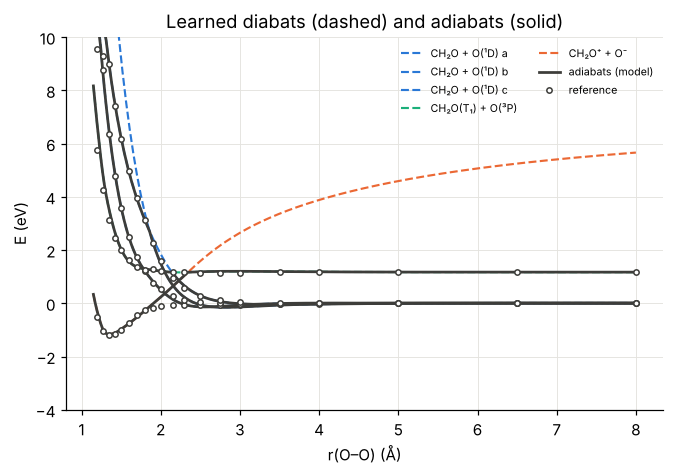

In [7]:
Md = framed.matrix(C).detach().numpy()
P.diabat_plot(x, np.diagonal(Md, axis1=1, axis2=2), framed.predict(C), fr.diabat_labels, [d.kind for d in diabats],
              ref_x=r[eq], ref=ref.energies[eq], xlabel='r(O–O) (Å)', ylabel='E (eV)', ylim=(-4, 10)); plt.show()

In [8]:
from diabml.ui import cut_explorer
cut_explorer(lambda x, angle: np.c_[x, np.full_like(x, angle)], {'framed CDNN': framed, 'CDNN': cdnn},
             x_range=(1.15, 6.0), fixed={'angle': (117.7, 65.0, 155.0)}, xlabel='r(O–O) (Å)')

interactive(children=(FloatSlider(value=117.7, description='angle', max=155.0, min=65.0, step=1.8), Output()),…

<function diabml.ui.cut_explorer.<locals>.draw(**kw)>

## Where to go next (all supported by the backend's structure)

- **Diabatic restraints from the diagnostics.** The charge on the terminal O is a natural label for the ionic
  structure; adding a loss term that ties the ionic diabat's population to it moves the model from 'compatible'
  towards 'diabatic' (the DDNN idea of Shu & Truhlar, 2020).
- **More coordinates.** C–O stretch, torsion and the H motions; the frame's switch only needs the O–O distance.
- **More channels.** Isomerisation to dioxirane (small ∠COO) and the triplet manifold are separate frames or more structures.
- **Better references.** XMS-CASPT2 or MRCI on top of the same active space.